# Cinemática directa: dónde queda el vaso para cada juego de ángulos

**Taller de Proyecto I (E0306) — 2.º cuatrimestre 2026 — Grupo N.º 3**

---

## Alcance

Hasta acá el brazo está dimensionado para el **peor caso estático**: una sola pose, la de
máximo esfuerzo. Este cuaderno responde la pregunta complementaria, que es la que necesita
el firmware: **dados los cuatro ángulos, dónde queda el vaso.**

Resuelve cinco cosas:

1. La convención de ángulos, que la documentación tenía contradictoria.
2. La fórmula de la cinemática directa.
3. La misma cadena por **Denavit-Hartenberg**, que es el método sistemático: sirve de
   verificación independiente y deja el formalismo escrito.
4. Qué alcanza el brazo **con los recorridos que dejó la transmisión**, que son bastante
   menos que 180° por eje.
5. Dónde ubicar la ventana de 60° del hombro, que nadie había fijado.

Los datos de entrada vienen del cuaderno de dimensionamiento: `L1 = L2 = 120 mm`,
`L3 = 85 mm`, y recorridos de **360° en la base, 60° en el hombro, 120° en el codo y 270°
en la muñeca**. Todo usa solo `math`.

> **El cero de alturas está en la mesa**, no en la tapa de la caja, y el vaso se toma y se
> deposita **sobre la mesa**. Es la referencia física: el brazo y el vaso apoyan en la
> misma superficie. Con el vaso en la mesa la caja pasa a ser un **obstáculo**, y eso
> cambia el resultado.

---

# 1. La convención, que había que resolver primero

El cuaderno de dimensionamiento dice dos cosas que no pueden ser ciertas a la vez:

> «Medimos `q2`, `q3` y `q4` **desde la vertical**.»

> «La muñeca mantiene el recipiente derecho con `q4 = 90 − q2 − q3`.»

Si los tres se midieran desde la vertical, para poner la pinza horizontal bastaría
`q4 = 90`, y la fórmula no tendría sentido. La fórmula solo cierra si **`q3` y `q4` son
relativos al eslabón anterior**.

Hay una tercera afirmación que desempata, y es del propio reparto de dientes:

> «La muñeca debe compensar la **suma** de los recorridos del hombro y del codo»,
> 60° + 120° = 180°, y por eso se le dieron 270°.

Si los ángulos fueran absolutos, la muñeca no tendría que compensar nada: su ángulo ya
sería su orientación. Que el presupuesto de recorrido sea la suma **prueba que el diseño
se hizo con ángulos relativos**.

| Ángulo | Se mide | Cero en |
|---|---|---|
| `q1` | alrededor del eje vertical | una dirección de referencia cualquiera |
| `q2` | **desde la vertical** | brazo apuntando hacia arriba |
| `q3` | **desde el eslabón anterior** | codo estirado |
| `q4` | **desde el eslabón anterior** | muñeca estirada |

Los ángulos **absolutos** respecto de la vertical son entonces las sumas parciales:
$\alpha_2 = q_2$, $\alpha_{23} = q_2 + q_3$, $\alpha_{234} = q_2 + q_3 + q_4$.

> **Errata a corregir**: la frase del cuaderno de dimensionamiento. El resto de ese
> cuaderno no cambia, porque el cálculo de pares usa el peor caso geométrico y no los
> ángulos.

---

# 2. La fórmula: sumar los eslabones como vectores

El método sistemático para una cadena serial es Denavit-Hartenberg: cuatro parámetros por
eslabón y un producto de matrices 4×4. Es lo que corresponde cuando los ejes están
**cruzados en el espacio**, porque ahí la geometría a ojo se vuelve inmanejable.

Este brazo no está en ese caso, y tiene una estructura que lo simplifica entero:

- **Tres ejes paralelos** entre sí: hombro, codo y muñeca giran todos alrededor de ejes
  horizontales paralelos, así que los tres eslabones se mueven **en un mismo plano**.
- **Un eje perpendicular**: la base gira ese plano alrededor de la vertical.

Entonces la cadena se parte en dos problemas que se resuelven por separado: un brazo plano
de tres eslabones, y una rotación. En el plano, la posición de la punta es simplemente la
**suma de los tres eslabones como vectores**, cada uno con su ángulo absoluto:

$$r = L_1\,\mathrm{sen}\,\alpha_2 + L_2\,\mathrm{sen}\,\alpha_{23} + L_3\,\mathrm{sen}\,\alpha_{234}$$
$$z = h_{hombro} + L_1\cos\alpha_2 + L_2\cos\alpha_{23} + L_3\cos\alpha_{234}$$

y después se rota con la base: $x = r\cos q_1$, $y = r\,\mathrm{sen}\,q_1$.

Esto **no es una aproximación**: es exacto, y se puede revisar a mano. Son cuatro líneas en
vez de cuatro matrices, el firmware las ejecuta sin librerías, y cualquiera del grupo puede
auditarlas.

Dicho eso, **que el método no haga falta no es razón para no hacerlo**. La sección 3 arma
la cadena completa por Denavit-Hartenberg y compara las dos formulaciones en 20 000
configuraciones al azar: es la verificación más independiente que puedo hacer de estas
cuatro líneas, porque usa otra convención de ejes, otros ángulos y otro producto de
matrices. Si hubiera un error de signo o de convención, aparece ahí.

In [1]:
import math, random

L1, L2, L3 = 120.0, 120.0, 85.0          # mm
H_HOMBRO = 190.0                         # altura del hombro SOBRE LA MESA:
                                         # 100 de caja + 90 de pedestal (seccion 5)

def directa(q1, q2, q3, q4):
    '''Posicion de la punta [mm] y orientacion del ultimo eslabon [rad].
       q1 sobre el eje vertical; q2 desde la vertical; q3 y q4 relativos.'''
    a2, a23, a234 = q2, q2 + q3, q2 + q3 + q4    # angulos absolutos
    r = L1*math.sin(a2) + L2*math.sin(a23) + L3*math.sin(a234)
    z = H_HOMBRO + L1*math.cos(a2) + L2*math.cos(a23) + L3*math.cos(a234)
    return r*math.cos(q1), r*math.sin(q1), z, a234

In [2]:
def mostrar(nombre, q1, q2, q3, q4):
    x, y, z, a = directa(*[math.radians(v) for v in (q1, q2, q3, q4)])
    print(f"{nombre:<32}{x:>8.1f}{y:>8.1f}{z:>8.1f}"
          f"{math.degrees(a):>14.0f} deg")

print(f"{'configuracion':<32}{'x':>8}{'y':>8}{'z':>8}"
      f"{'ultimo eslabon':>18}")
print('-' * 70)
mostrar("todo a cero: brazo vertical",      0,   0,   0,  0)
mostrar("estirado horizontal",              0,  90,   0,  0)
mostrar("estirado, base a 90 deg",         90,  90,   0,  0)
mostrar("hombro 90, codo -90",              0,  90, -90,  0)
mostrar("pinza horizontal: q4 = 90-q2-q3",  0,  60,  20, 10)

configuracion                          x       y       z    ultimo eslabon
----------------------------------------------------------------------
todo a cero: brazo vertical          0.0     0.0   515.0             0 deg
estirado horizontal                325.0     0.0   190.0            90 deg
estirado, base a 90 deg              0.0   325.0   190.0            90 deg
hombro 90, codo -90                120.0     0.0   395.0             0 deg
pinza horizontal: q4 = 90-q2-q3    307.1     0.0   270.8            90 deg


Los casos de control dan lo que tienen que dar: con todo a cero el brazo está vertical y la
punta a 515 mm sobre la mesa, que es `h_hombro + L1 + L2 + L3`; estirado horizontal da
325 mm de radio, que es el alcance del cuaderno de dimensionamiento, a la altura del
hombro. Es la primera verificación, la de que los números tienen sentido físico; la
segunda, la formal, es la sección que sigue.

---

# 3. El mismo brazo por Denavit-Hartenberg

La sección 2 llega a la fórmula mirando la geometría: tres ejes paralelos hacen un brazo
plano, el cuarto lo rota, y la punta es la suma de los eslabones como vectores. Es correcto
y es lo que programa el firmware, pero tiene una debilidad como argumento: **lo verifiqué
con el mismo razonamiento con el que lo escribí**. Si el error estuviera en cómo pienso la
cadena, no lo veo.

Denavit-Hartenberg no comparte nada de eso. Fija los sistemas de referencia con reglas
propias, mide los ángulos desde otros ejes y compone otras matrices. Si las dos
formulaciones coinciden, el resultado no depende de cómo se lo mire.

Y hay una segunda razón para escribirlo, que no es de verificación sino de método: es la
herramienta estándar para cadenas seriales, este brazo es un caso lo bastante simple para
seguirla a mano y lo bastante completo —tiene un eje perpendicular a los otros tres— para
que la tabla no quede trivial. Lo que viene después de la cinemática directa —el jacobiano,
cualquier eje nuevo— se escribe sobre esta tabla, no sobre las cuatro líneas de la
sección 2.

## 3.1 Los cuatro parámetros

La idea del método es que **la posición relativa de dos eslabones consecutivos siempre se
puede describir con cuatro números**, si los sistemas de referencia se eligen con estas dos
reglas:

- `z_i` sobre el **eje de giro** de la articulación siguiente;
- `x_i` sobre la **normal común** entre `z_(i-1)` y `z_i`.

Con esa elección, pasar del sistema `i-1` al `i` es siempre la misma secuencia —girar y
trasladar sobre `z`, trasladar y girar sobre `x`— y nunca hacen falta más de cuatro
parámetros:

| Parámetro | Qué es | Sobre qué eje |
|---|---|---|
| `θ_i` | ángulo de `x_(i-1)` a `x_i` | giro sobre `z_(i-1)` — **es la variable de la articulación** |
| `d_i` | corrimiento del origen | traslación sobre `z_(i-1)` |
| `a_i` | largo del eslabón | traslación sobre `x_i` |
| `α_i` | torsión entre ejes de giro | giro sobre `x_i` |

$$A_i = \mathrm{Rot}_z(\theta_i)\; T_z(d_i)\; T_x(a_i)\; \mathrm{Rot}_x(\alpha_i)$$

y la cinemática directa completa es el producto $T = A_1 A_2 A_3 A_4$, cuya última columna
es la posición de la punta y cuya submatriz 3×3 es la orientación de la pinza.

De los cuatro parámetros, **uno por eslabón es la variable** —acá siempre `θ`, porque las
cuatro articulaciones son de giro— y los otros tres son **constantes de construcción**: se
miden sobre la pieza y no cambian nunca.

## 3.2 La tabla de este brazo

Hay cinco sistemas: el 0 en la base, sobre la mesa; el 1 en el hombro; el 2 en el codo; el 3
en la muñeca; y el 4 en la punta de los dedos.

| i | Articulación | `θ_i` | `d_i` [mm] | `a_i` [mm] | `α_i` |
|---|---|---|---|---|---|
| 1 | base | `q1` | **190** | 0 | **−90°** |
| 2 | hombro | **`q2 − 90°`** | 0 | **120** | 0 |
| 3 | codo | `q3` | 0 | **120** | 0 |
| 4 | muñeca | `q4` | 0 | **85** | 0 |

Leída en palabras, fila por fila:

1. **La base** gira `q1` sobre la vertical y el origen sube `d1 = 190 mm` hasta el hombro,
   que es la altura sobre la mesa de la sección 5. `a1 = 0` porque los ejes de la base y del
   hombro **se cortan**: no hay corrimiento lateral. La torsión `α1 = −90°` es la que
   convierte el eje vertical de la base en el eje horizontal del hombro, y es la única
   torsión del brazo.
2. **El hombro, el codo y la muñeca** tienen los tres `d = 0` y `α = 0`: `d = 0` porque los
   eslabones no tienen corrimiento lateral, y `α = 0` porque **los tres ejes son
   paralelos**. Lo único que queda de cada fila es el largo del eslabón, en `a`.

Las tres filas con `α = 0` son, justamente, el brazo plano de la sección 2: **la tabla
muestra sola la estructura del brazo**. Dónde está la torsión y dónde no es lo que separa un
brazo que se puede resolver a ojo de uno que no.

### Los dos cambios de variable

La tabla no usa los ángulos del brazo tal cual, y vale entender por qué:

- **`θ2 = q2 − 90°`.** El método mide `θ2` desde `x1`, que después de la torsión queda
  **horizontal**, apuntando hacia afuera. Nosotros medimos `q2` **desde la vertical**
  (sección 1). Son los mismos 90° de diferencia, siempre: una constante de la tabla, no un
  cambio de criterio.
- **`θ3 = q3` y `θ4 = q4`, sin corrección.** Esto no es casualidad ni elección: el método
  mide `θ_i` desde `x_(i-1)`, o sea **desde el eslabón anterior**. Es exactamente la
  convención relativa que la sección 1 tuvo que deducir de una contradicción de la
  documentación, y acá aparece impuesta por el formalismo. Si hubiera elegido `α1 = +90°` en
  vez de `−90°` me quedarían `θ3 = −q3` y `θ4 = −q4`: el signo de la torsión es lo que fija
  el sentido positivo de los tres ejes paralelos.

In [3]:
# ---- Denavit-Hartenberg: cuatro parametros por eslabon -----------------
def mul(A, B):
    return [[sum(A[i][k]*B[k][j] for k in range(4)) for j in range(4)]
            for i in range(4)]

def rot_z(a):
    c, s = math.cos(a), math.sin(a)
    return [[c, -s, 0, 0], [s, c, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]]

def rot_x(a):
    c, s = math.cos(a), math.sin(a)
    return [[1, 0, 0, 0], [0, c, -s, 0], [0, s, c, 0], [0, 0, 0, 1]]

def trasl(x, z):
    return [[1, 0, 0, x], [0, 1, 0, 0], [0, 0, 1, z], [0, 0, 0, 1]]

def eslabon_dh(theta, d, a, alpha):
    '''A_i = Rot_z(theta) . Tz(d) . Tx(a) . Rot_x(alpha)'''
    return mul(mul(rot_z(theta), trasl(0.0, d)),
               mul(trasl(a, 0.0), rot_x(alpha)))

def tabla_dh(q1, q2, q3, q4):
    '''theta, d, a, alpha. Las tres ultimas columnas son de construccion.'''
    return [(q1,             H_HOMBRO, 0.0, -math.pi/2),   # base
            (q2 - math.pi/2, 0.0,      L1,   0.0),         # hombro
            (q3,             0.0,      L2,   0.0),         # codo
            (q4,             0.0,      L3,   0.0)]         # muneca

def directa_dh(q1, q2, q3, q4):
    '''Los cinco sistemas: base, hombro, codo, muneca y punta.'''
    T = [[1.0 if i == j else 0.0 for j in range(4)] for i in range(4)]
    cadena = [T]
    for fila in tabla_dh(q1, q2, q3, q4):
        T = mul(T, eslabon_dh(*fila))
        cadena.append(T)
    return cadena

In [4]:
# ---- verificacion: posicion, orientacion y sistemas intermedios --------
random.seed(11)
peor_pos, peor_ori = 0.0, 0.0
for _ in range(20000):
    q = [random.uniform(-math.pi, math.pi) for _ in range(4)]
    x, y, z, a234 = directa(*q)
    T = directa_dh(*q)[-1]
    peor_pos = max(peor_pos, max(abs(u - v) for u, v in
                                 zip((x, y, z), (T[0][3], T[1][3], T[2][3]))))
    # el eje x del ultimo sistema es el eslabon: su componente vertical es cos(a234)
    peor_ori = max(peor_ori, abs(T[2][0] - math.cos(a234)))

print("20 000 configuraciones al azar, geometrico contra Denavit-Hartenberg")
print(f"  maxima discrepancia en posicion   : {peor_pos:.1e} mm")
print(f"  maxima discrepancia en orientacion: {peor_ori:.1e}")

# los sistemas intermedios son el codo y la muneca, que es lo que mira la
# guarda de la seccion 6: conviene verificarlos y no solo la punta
q2, q3 = math.radians(80.0), math.radians(40.0)
q4 = math.pi/2 - q2 - q3
a23 = q2 + q3
geom = [(0.0, H_HOMBRO),
        (L1*math.sin(q2), H_HOMBRO + L1*math.cos(q2)),
        (L1*math.sin(q2) + L2*math.sin(a23),
         H_HOMBRO + L1*math.cos(q2) + L2*math.cos(a23))]
geom.append((geom[2][0] + L3, geom[2][1]))      # pinza horizontal

print(f"\n{'sistema':<12}{'r [mm]':>10}{'z [mm]':>10}"
      f"{'r geometrico':>16}{'z geometrico':>16}")
print('-' * 64)
for nombre, T, (r, z) in zip(('hombro', 'codo', 'muneca', 'punta'),
                             directa_dh(0.0, q2, q3, q4)[1:], geom):
    print(f"{nombre:<12}{math.hypot(T[0][3], T[1][3]):>10.1f}{T[2][3]:>10.1f}"
          f"{r:>16.1f}{z:>16.1f}")

20 000 configuraciones al azar, geometrico contra Denavit-Hartenberg
  maxima discrepancia en posicion   : 2.1e-13 mm
  maxima discrepancia en orientacion: 1.4e-15

sistema         r [mm]    z [mm]    r geometrico    z geometrico
----------------------------------------------------------------
hombro             0.0     190.0             0.0           190.0
codo             118.2     210.8           118.2           210.8
muneca           222.1     150.8           222.1           150.8
punta            307.1     150.8           307.1           150.8


## 3.3 Por qué tenía que coincidir

El acuerdo no es casualidad, y se puede ver en el álgebra sin hacer cuentas. Las tres filas
del brazo plano tienen `d = 0` y `α = 0`, así que cada una se reduce a

$$A_i = \mathrm{Rot}_z(\theta_i)\, T_x(a_i)$$

Al multiplicar tres de esas, los giros se acumulan —son todos sobre el mismo eje, así que
los ángulos se suman— y cada traslación sale rotada por los giros que la preceden. El
producto queda

$$A_2A_3A_4 = \mathrm{Rot}_z(\theta_2+\theta_3+\theta_4)\ \text{con el origen en}\quad
a_2\,u(\theta_2) + a_3\,u(\theta_2{+}\theta_3) + a_4\,u(\theta_2{+}\theta_3{+}\theta_4)$$

donde $u(\varphi)$ es el versor que apunta a $\varphi$. Es decir: **la suma de los
eslabones como vectores, cada uno con su ángulo absoluto**, que es palabra por palabra la
fórmula de la sección 2. Y la primera fila, la única con torsión, es la que aporta la
rotación de la base y la altura del hombro.

Dicho de otro modo: la fórmula geométrica no es un atajo ni una aproximación, es **el
producto de matrices ya simplificado**. Denavit-Hartenberg llega al mismo lugar haciendo las
cuentas que acá se pueden saltear porque los ejes son paralelos.

Que coincidan los **sistemas intermedios** importa más de lo que parece: la guarda de la
sección 6 no mira la punta sino el codo y la muñeca, así que verificarlos es verificar la
guarda, no sólo el resultado final.

## 3.4 Qué aporta y qué no

**No cambia nada del firmware.** Las cuatro líneas de la sección 2 siguen siendo lo que se
programa: dan el mismo resultado con cuatro senos y cuatro cosenos, en vez de los tres
productos de matrices 4×4 —192 multiplicaciones— que pide la tabla, y se auditan a mano.
Tener la tabla no es razón para usarla.

**Lo que aporta es confianza y método.** Confianza, porque es una verificación con otra
convención de ejes, otros ángulos y otro producto de matrices: para que las dos coincidan en
10⁻¹³ mm estando mal, el error tendría que estar en las dos a la vez. Y método, porque la
tabla es la entrada natural de todo lo que viene después:

- **La cinemática inversa.** Para este brazo tiene solución cerrada y no hace falta, pero si
  no la tuviera, los métodos numéricos piden la cadena en forma matricial.
- **El jacobiano**, que relaciona velocidad de articulación con velocidad de la punta y
  dice dónde el brazo pierde autoridad. Sale derivando el producto, no la fórmula
  geométrica, y está hecho en `Jacobiano_brazo.ipynb`, que además verifica esta tabla
  contra el Robotics Toolbox de Peter Corke.
- **Cualquier eje que se agregue.** Si a la muñeca se le sumara un giro sobre su propio eje
  —para rotar el vaso, por ejemplo—, los ejes dejan de ser paralelos, la descomposición en
  brazo plano más rotación **se rompe**, y entonces el método pasa de ser una verificación a
  ser la única forma razonable de escribir la cinemática. La tabla ya está armada: sería
  agregarle una fila con `α = 90°`.

Y queda una lectura de método que no es menor. La sección 1 tuvo que **deducir** la
convención de ángulos a partir de una contradicción de la documentación y del reparto de
dientes de la transmisión. Acá la misma convención aparece **impuesta por la tabla**:
Denavit-Hartenberg mide cada `θ` desde el eslabón anterior y no permite otra lectura. Es la
confirmación más limpia de esa decisión.

---

# 4. La pinza horizontal simplifica el problema a dos eslabones

Durante el traslado la muñeca mantiene la pinza horizontal, o sea
$\alpha_{234} = 90°$. Reemplazando en las dos fórmulas pasa algo cómodo:

$$r = L_1\,\mathrm{sen}\,\alpha_2 + L_2\,\mathrm{sen}\,\alpha_{23} + L_3
\qquad
z = h_{hombro} + L_1\cos\alpha_2 + L_2\cos\alpha_{23}$$

El tercer eslabón **aporta una constante al radio y nada a la altura**. Es decir: en modo
de traslado el brazo se comporta como un **manipulador plano de dos eslabones**, corrido
85 mm en `r` y 90 mm en `z`. Toda la discusión del espacio de trabajo se hace sobre eso.

---

# 5. La caja, de altura y de obstáculo

Antes de barrer el espacio de trabajo hay que resolver tres números que la documentación
tenía mal.

**La caja no mide 12,5 cm de alto.** El cuaderno de dimensionamiento dice que «la caja
levanta el hombro unos 12,5 cm sobre la mesa», pero 12,5 cm es el **radio** de la caja de
25 × 25, no su altura. La altura la fija la fuente: una ATX en formato PS/2 mide
150 × 86 × 140 mm, así que la caja no puede medir menos de unos 100 mm.

**`Z0` no va de la mesa al hombro.** La tabla de geometría define `Z0 = 9 cm` como «de la
mesa al eje del hombro», pero el mismo cuaderno pone la caja debajo. Los 90 mm son el
**pedestal sobre la tapa**, y el hombro queda a 100 + 90 = **190 mm de la mesa**.

**La caja de 25 × 25 es más grande de lo necesario.** Su tamaño salió del criterio de
vuelco, `m·R ≥ 1,5·τ_hombro`, resuelto subiendo `R` en vez de `m`. Pero la masa se puede
agregar: una chapa de acero en el piso cuesta casi nada y deja reducir la caja a lo justo
para alojar la fuente. Y eso importa mucho, porque **con el vaso en la mesa la caja es un
obstáculo**: todo lo que quede a menos de su radio es inalcanzable.

In [5]:
TAU_HOMBRO, FS_VUELCO = 11.96, 1.5          # kg.cm, y el factor del criterio
PSU_W, PSU_H, PSU_D = 150.0, 86.0, 140.0    # fuente ATX, formato PS/2
M_PSU = 1.2                                 # kg, el extremo liviano del rango
RHO_ACERO = 7.85e-3                         # kg/cm3

CAJA_W, CAJA_D = PSU_W + 2*7, PSU_D + 2*7   # paredes de 7 mm
CAJA_H = PSU_H + 2*5 + 4                    # piso, tapa y holgura
R_VUELCO = min(CAJA_W, CAJA_D)/2            # la semidimension menor: el peor caso
R_CAJA = math.hypot(CAJA_W, CAJA_D)/2       # la esquina: el obstaculo
R_GUARDA = math.ceil(R_CAJA)                # redondeado hacia afuera, para el firmware

m_necesaria = FS_VUELCO*TAU_HOMBRO/(R_VUELCO/10)
falta = max(0.0, m_necesaria - M_PSU)
espesor = falta/(RHO_ACERO*(CAJA_W/10)*(CAJA_D/10))

print(f"caja            : {CAJA_W:.0f} x {CAJA_D:.0f} x {CAJA_H:.0f} mm")
print(f"radio de vuelco : {R_VUELCO:.0f} mm")
print(f"radio de esquina: {R_CAJA:.1f} mm  (es el que hace de obstaculo)")
print(f"radio de guarda : {R_GUARDA:.0f} mm  (el de esquina, redondeado hacia afuera)")
print(f"masa necesaria  : {m_necesaria:.2f} kg")
print(f"la fuente aporta {M_PSU:.1f} kg -> faltan {falta:.2f} kg")
print(f"   = chapa de acero de {espesor*10:.0f} mm en el piso de la caja")
print(f"\ncontra la caja de 250 x 250 original, el obstaculo baja de "
      f"{math.hypot(250.0, 250.0)/2:.0f} a {R_CAJA:.0f} mm de radio")

caja            : 164 x 154 x 100 mm
radio de vuelco : 77 mm
radio de esquina: 112.5 mm  (es el que hace de obstaculo)
radio de guarda : 113 mm  (el de esquina, redondeado hacia afuera)
masa necesaria  : 2.33 kg
la fuente aporta 1.2 kg -> faltan 1.13 kg
   = chapa de acero de 6 mm en el piso de la caja

contra la caja de 250 x 250 original, el obstaculo baja de 177 a 112 mm de radio


---

# 6. El espacio de trabajo real

Ahora sí se puede barrer. El vaso se apoya en la mesa, mide 90 mm y la pinza lo toma 20 mm
bajo el borde, así que **la punta trabaja a z = 70 mm**, o sea 120 mm por debajo del
hombro. La ventana de 60° del hombro hay que **ubicarla**, y acá hay dos criterios que
compiten: cuánto radio cubre, y cuánto puede levantar el vaso una vez agarrado.

In [6]:
PEDESTAL = 90.0                       # mm sobre la tapa
assert abs(H_HOMBRO - (CAJA_H + PEDESTAL)) < 1e-9   # cierra con la seccion 2
Z_GARRA = 70.0                        # altura de la punta al agarrar
REC_H, REC_C, REC_M = 60.0, 120.0, 270.0

def articulaciones(q2, q3):
    '''Codo, muneca y punta en el plano del brazo, con la pinza horizontal.'''
    a23 = q2 + q3
    codo = (L1*math.sin(q2), H_HOMBRO + L1*math.cos(q2))
    mun = (codo[0] + L2*math.sin(a23), codo[1] + L2*math.cos(a23))
    return codo, mun, (mun[0] + L3, mun[1])

def libre(q2, q3):
    '''Ningun punto del brazo bajo la mesa ni dentro de la caja.'''
    return all(z >= 0 and not (z < CAJA_H and r < R_GUARDA)
               for r, z in articulaciones(q2, q3))

def barrer(h0, c0, N=240):
    '''Radios a la altura de agarre, y alturas alcanzables en r = 250.'''
    radios, alturas = [], []
    for i in range(N + 1):
        a2 = h0 + REC_H*i/N
        for j in range(N + 1):
            a3 = c0 + REC_C*j/N
            q2, q3 = math.radians(a2), math.radians(a3)
            if not libre(q2, q3):
                continue
            p = articulaciones(q2, q3)[2]
            if abs(p[1] - Z_GARRA) <= 1.0:
                radios.append(p[0])
            if abs(p[0] - 250.0) <= 1.5:
                alturas.append(p[1])
    return radios, alturas

print(f"{'ventana del hombro':>20}{'radio util a z=70':>22}{'recorrido':>12}"
      f"{'alzada sobre el agarre':>26}")
print('-' * 82)
for h0 in (35, 40, 45, 50, 55, 60):
    radios, alturas = barrer(h0, 0.0)
    if not radios or not alturas:
        print(f"{h0:>12.0f} a {h0+REC_H:<5.0f}   no llega")
        continue
    print(f"{h0:>12.0f} a {h0+REC_H:<5.0f}{min(radios):>14.0f} a "
          f"{max(radios):<6.0f}{max(radios)-min(radios):>10.0f}mm"
          f"{max(alturas)-Z_GARRA:>22.0f} mm")

  ventana del hombro     radio util a z=70   recorrido    alzada sobre el agarre
----------------------------------------------------------------------------------
          35 a 95              198 a 255           57mm                   296 mm
          40 a 100             198 a 272           74mm                   296 mm


          45 a 105             198 a 282           84mm                   116 mm
          50 a 110             198 a 288           90mm                   103 mm
          55 a 115             198 a 292           94mm                    90 mm


          60 a 120             198 a 293           95mm                    77 mm


El codo no cambia el resultado —probé de −45° a +30° y da lo mismo—, así que lo dejo de
**0° a 120°**, con el cero en el codo estirado.

La ventana del hombro sí, y el compromiso es claro: cuanto más baja, más levanta el vaso;
cuanto más alta, más radio cubre. **Adopto 50° a 110°**, que es donde las dos cosas son
cómodas: 91 mm de radio y 103 mm de alzada.

Vale una aclaración sobre cómo leer esos 91 mm. Si los dos puntos de la tarea están **al
mismo radio**, el traslado lo hace la base y el recorrido radial no es un requisito de
movimiento sino un **margen de tolerancia** para apoyar el vaso. 91 mm de tolerancia es
holgado.

In [7]:
H0, C0 = 50.0, 0.0

N = 300
permitidas, total = [], 0
for i in range(N + 1):
    a2 = H0 + REC_H*i/N
    for j in range(N + 1):
        a3 = C0 + REC_C*j/N
        total += 1
        if libre(math.radians(a2), math.radians(a3)):
            permitidas.append((a2, a3, articulaciones(math.radians(a2),
                                                      math.radians(a3))))

en_z = [v for v in permitidas if abs(v[2][2][1] - Z_GARRA) <= 1.0]
en_r = [v for v in permitidas if abs(v[2][2][0] - 250.0) <= 1.5]
q4 = [90 - v[0] - v[1] for v in permitidas]

print(f"VENTANA ADOPTADA: hombro {H0:.0f} a {H0+REC_H:.0f}, "
      f"codo {C0:.0f} a {C0+REC_C:.0f}\n")
print(f"  radio util a la altura de agarre : "
      f"{min(v[2][2][0] for v in en_z):.0f} a "
      f"{max(v[2][2][0] for v in en_z):.0f} mm")
print(f"  alzada en r = 250 mm             : hasta "
      f"{max(v[2][2][1] for v in en_r):.0f} mm, o sea "
      f"{max(v[2][2][1] for v in en_r) - Z_GARRA:.0f} sobre el agarre")
print(f"  recorrido de la muneca           : {min(q4):.0f} a {max(q4):.0f} grados, "
      f"{max(q4)-min(q4):.0f} de los {REC_M:.0f} disponibles")
print(f"  poses que pasan la guarda        : {100*len(permitidas)/total:.0f} %")
print(f"  punto mas bajo del brazo         : codo "
      f"{min(v[2][0][1] for v in permitidas):.0f} mm, muneca "
      f"{min(v[2][1][1] for v in permitidas):.0f} mm")

# El 86 % de arriba mira hombro y codo. Pero la muneca tambien tiene tope, y la
# pregunta que decide si la guarda hace falta es otra: de las poses con los
# CUATRO ejes dentro de su ventana, cuantas chocan igual.
REC_Q4 = (-108.0, 40.0)
en_ventana, chocan, peor = 0, 0, None
for i in range(N + 1):
    a2 = H0 + REC_H*i/N
    for j in range(N + 1):
        a3 = C0 + REC_C*j/N
        a4 = 90 - a2 - a3                       # muneca asistida
        if not REC_Q4[0] <= a4 <= REC_Q4[1]:
            continue
        en_ventana += 1
        if not libre(math.radians(a2), math.radians(a3)):
            chocan += 1
            mun = articulaciones(math.radians(a2), math.radians(a3))[1]
            if peor is None or mun[0] < peor[0][0]:   # la que mas se mete
                peor = (mun, a2, a3, a4)

print(f"\ncon los CUATRO ejes dentro de su ventana:")
print(f"  poses que violan la guarda       : {100*chocan/en_ventana:.1f} %")
print(f"  la mas profunda                  : hombro {peor[1]:.0f}, codo {peor[2]:.0f}, "
      f"muneca {peor[3]:.0f}")
print(f"     -> deja la muneca a r = {peor[0][0]:.0f} mm, z = {peor[0][1]:.0f} mm, "
      f"{CAJA_H - peor[0][1]:.0f} mm bajo la tapa")

VENTANA ADOPTADA: hombro 50 a 110, codo 0 a 120

  radio util a la altura de agarre : 198 a 289 mm
  alzada en r = 250 mm             : hasta 173 mm, o sea 103 sobre el agarre
  recorrido de la muneca           : -108 a 40 grados, 148 de los 270 disponibles
  poses que pasan la guarda        : 86 %
  punto mas bajo del brazo         : codo 149 mm, muneca 29 mm

con los CUATRO ejes dentro de su ventana:
  poses que violan la guarda       : 7.8 %
  la mas profunda                  : hombro 110, codo 88, muneca -108
     -> deja la muneca a r = 76 mm, z = 35 mm, 65 mm bajo la tapa


La **guarda** que aparece ahí hace falta, y conviene ser preciso con el porqué, porque es
fácil engañarse. El 14 % que descarta se mide sobre hombro y codo, pero la muñeca también
tiene tope, así que la pregunta honesta es: **con los cuatro ejes dentro de su ventana,
¿puede el brazo chocar?** La respuesta es sí, y en el **7,8 %** de las poses: la más
profunda es hombro 110°, codo 88° y muñeca −108° —los tres en su límite legal— y deja la
muñeca a 35 mm de la mesa y 76 mm del eje, o sea **65 mm por debajo de la tapa de la
caja**, bien adentro.

> ningún punto del brazo con `z < 100 mm` puede tener `r < 113 mm`

Los 113 mm son el radio de esquina de la caja, 112,5, redondeado hacia afuera: así el
firmware trabaja con un entero y la guarda queda del lado conservador.

En la práctica alcanza con vigilar la muñeca, que es el punto más bajo; el codo nunca baja
de 149 mm. Vale no confundir dos números: entre las poses que la guarda **sí** permite, el
punto más bajo del brazo es la muñeca a 29 mm de la mesa, pero ahí está a 114 mm de radio,
rozando la esquina de la caja por fuera.

---

# 7. Resultado

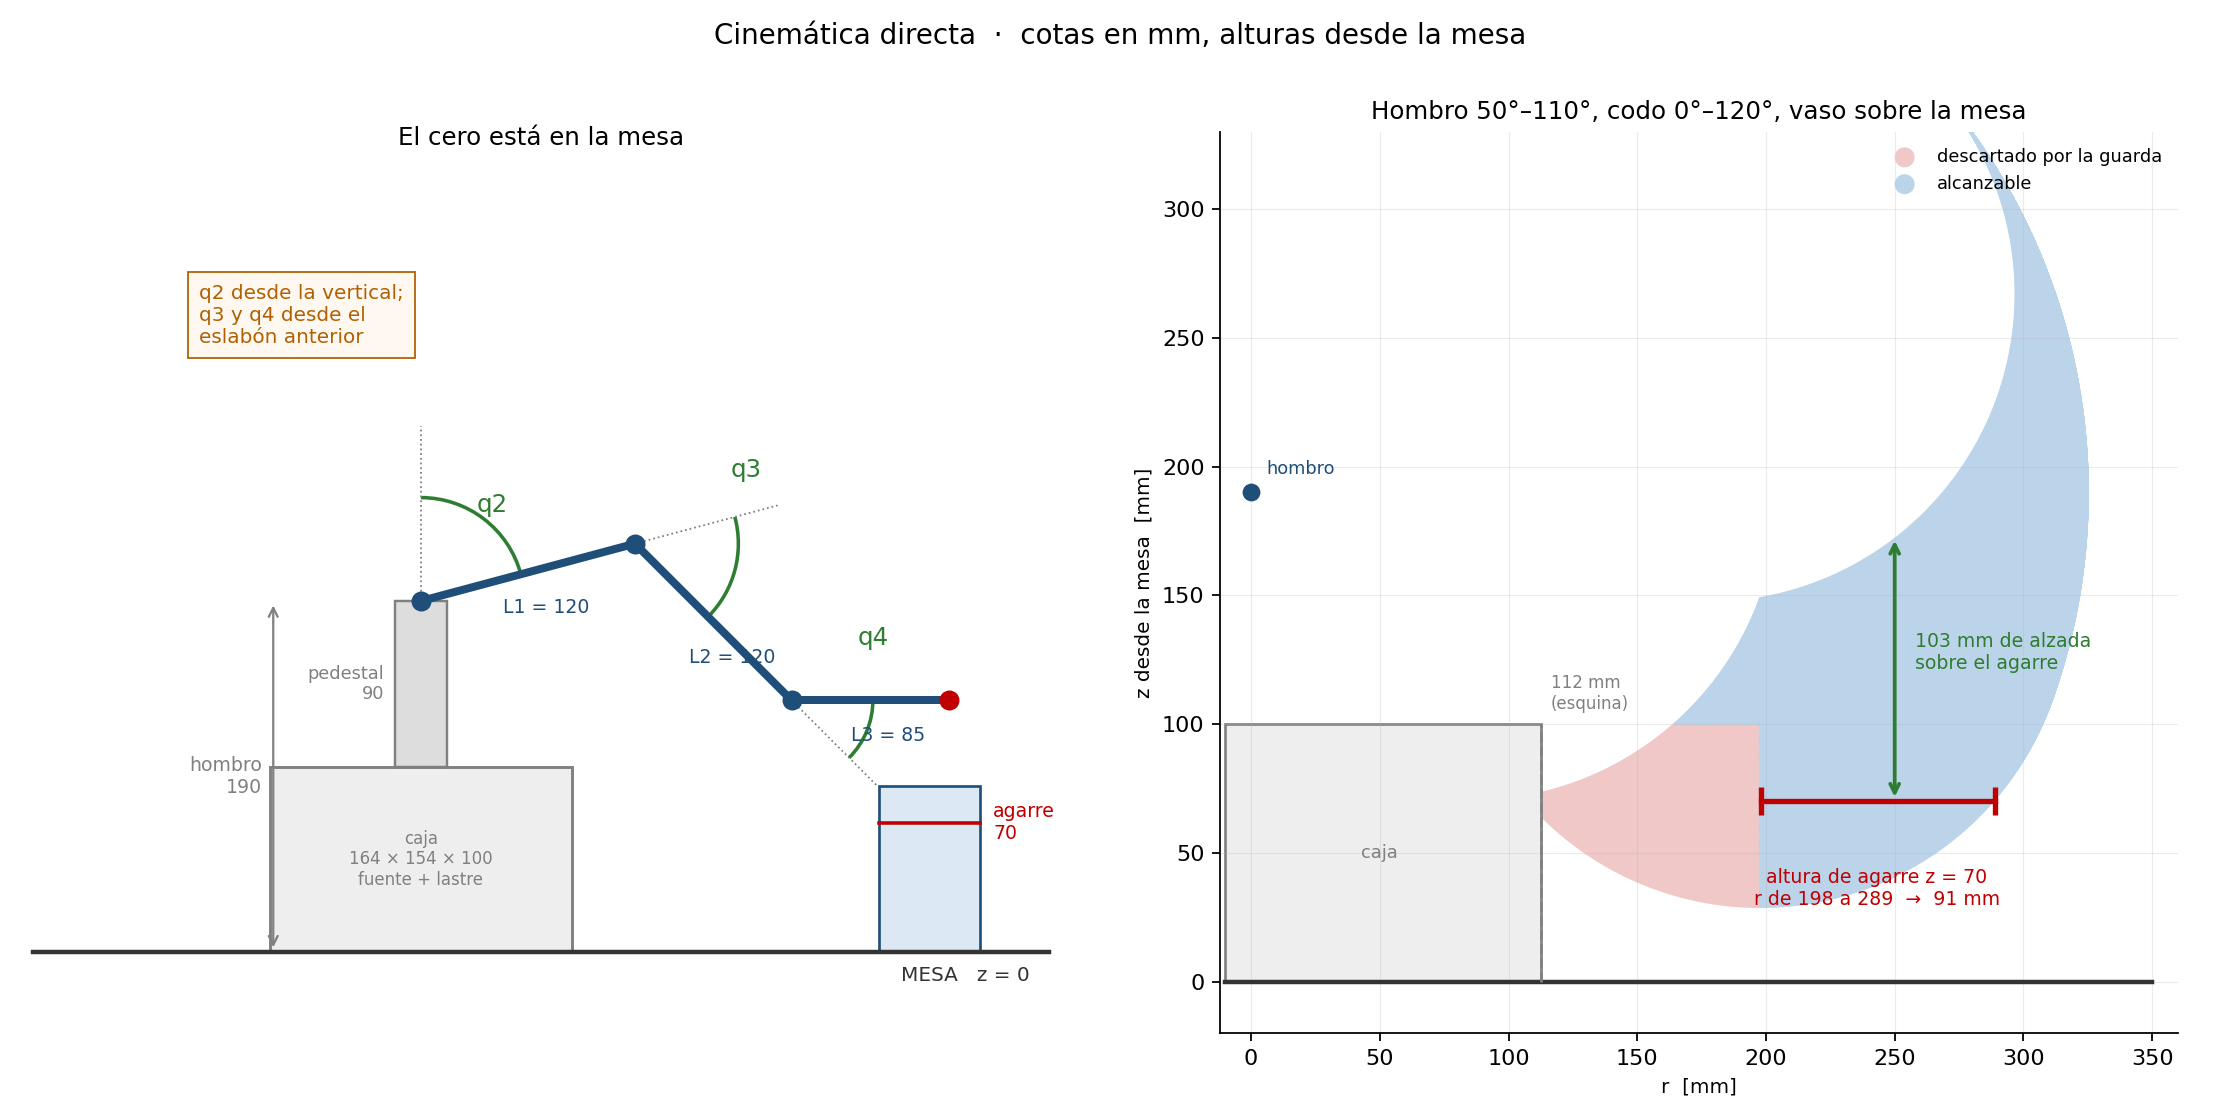

**Figura 1.** Convención de ángulos y espacio de trabajo. Alturas desde la mesa, cotas en mm.

| | |
|---|---|
| Caja | 164 × 154 × 100 mm, con chapa de acero de 6 mm en el piso |
| Altura del hombro sobre la mesa | 190 mm |
| Ventana del hombro | **50° a 110°** |
| Ventana del codo | **0° a 120°** |
| Recorrido de la muñeca | de −108° a +40°, 148° de los 270° disponibles |
| Base | 360°, sin restricción |
| Radio útil a la altura de agarre | de 198 a 289 mm |
| Recorrido radial | 91 mm |
| Alzada sobre el agarre en r = 250 mm | 103 mm |
| Guarda contra la caja | ningún punto con `z < 100` puede tener `r < 113` |

---

# 8. Lo que esto le dice a la tarea

El cuaderno de dimensionamiento justificó los eslabones de 12 cm diciendo que

> «el brazo toma el recipiente en un punto y lo deposita a unos 20 cm **sin mover la
> base**».

Con los recorridos reales **eso no se cumple radialmente**: el recorrido radial disponible
a la altura de agarre es de 91 mm, no de 200.

La tarea igual se cumple, pero por otro camino: **girando la base**. Dos puntos al mismo
radio, separados un ángulo $\varphi$, quedan a $2r\,\mathrm{sen}(\varphi/2)$.

In [8]:
print("separacion de 200 mm girando la base\n")
print(f"{'radio':>8}{'giro de base necesario':>26}")
print('-' * 34)
for r in (220, 250, 289):
    print(f"{r:>6} mm{2*math.degrees(math.asin(100/r)):>21.0f} grados")
print("\nla base tiene 360 grados: sobra")

separacion de 200 mm girando la base

   radio    giro de base necesario
----------------------------------
   220 mm                   54 grados
   250 mm                   47 grados
   289 mm                   40 grados

la base tiene 360 grados: sobra


O sea que el requerimiento 3.1.4 —«tomar el recipiente de una posición y depositarlo en
otra **sin desplazar la base**»— se cumple: *desplazar* la base es mover el robot de lugar,
y eso no hace falta. Lo que hay que corregir es la **justificación**, que atribuye los
200 mm a un recorrido radial que el brazo no tiene.

Conviene además elegir los dos puntos **al mismo radio**, porque ahí el movimiento es un
giro puro de la base y los otros tres ejes quedan quietos: el vaso se mantiene a altura
constante sin que la muñeca tenga que compensar nada.

---

# 9. Lo que le queda al firmware

| Requerimiento | Valor |
|---|---|
| Convención | `q2` desde la vertical; `q3` y `q4` desde el eslabón anterior |
| Tope del hombro | 50° a 110° |
| Tope del codo | 0° a 120° |
| Tope de la muñeca | −108° a +40° |
| Muñeca asistida | `q4 = 90° − q2 − q3` |
| Guarda contra la caja | ningún punto del brazo con `z < 100 mm` puede tener `r < 113 mm`, evaluada antes de aceptar un incremento |
| Traslado preferente | girar la base con los otros tres ejes quietos |

La guarda es lo único nuevo respecto de lo que ya estaba: **los topes por eje no alcanzan**,
porque la colisión aparece con los dos ejes dentro de su rango. Hay que evaluarla en cada
ciclo, antes de aplicar el incremento que pide el joystick. En la práctica alcanza con
vigilar la altura de la muñeca, que es el punto más bajo del brazo.

---

# 10. Lo que falta

1. **La cinemática inversa**, que es el paso siguiente: dado un punto, qué ángulos. Con dos
   eslabones iguales tiene solución cerrada, y hay que elegir entre codo arriba y codo
   abajo según cuál caiga dentro de la ventana.
2. **Medir el cero de cada eje** al montar. Toda esta cinemática está escrita en ángulos de
   articulación: la correspondencia con el ancho de pulso de cada servo sale del ensayo de
   barrido, que sigue pendiente.
3. **Verificar la ventana del hombro contra el montaje real**, una vez que estén las piezas:
   acá está elegida sobre el modelo, y el tope mecánico tiene que coincidir.
4. **Revisar la interferencia del brazo consigo mismo**, que este cuaderno no mira: solo
   verifica contra la caja y la mesa.
5. **Pesar la fuente y medir la caja** una vez construida, para confirmar el criterio de
   vuelco con el lastre y el radio de esquina que hace de obstáculo.